# Exploratory data analysis: Penmanshiel

Penmanshiel is a 14-turbine onshore wind farm in the Scottish Borders (Senvion MM82, 2.05 MW each; there is no turbine 03). The data are the Greenbyte exports released as open data, converted to Parquet by `python penmanshiel_process.py`:

| File | Contents |
|---|---|
| `turbines.parquet` | static metadata, one row per turbine |
| `feature_description.parquet` | SCADA column name -> original label, signal, stat, unit |
| `scada/<turbine_id>.parquet` | 10-minute SCADA, 2016-06 to 2023-12 |
| `status/<turbine_id>.parquet` | status / event log |

Unlike CARE to Compare there are **no fault labels**. The status log is the only event record, so this notebook looks at what it contains and how far it can stand in for labels.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

DATA = Path("data/Penmanshiel")
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

# Same categorical palette as eda.ipynb (colour-blind-checked), used in fixed order.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#e6e5e0", "#b5b4ad"


def style_ax(ax, grid_axis="both"):
    # Recessive grid and axes, as in eda.ipynb.
    if grid_axis:
        ax.grid(True, axis=grid_axis, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.title.set_color(INK)


turbines = pd.read_parquet(DATA / "turbines.parquet")
features = pd.read_parquet(DATA / "feature_description.parquet")
TURBINE_IDS = turbines["turbine_id"].tolist()
label = lambda t: f"T{t:02d}"
status = pd.concat([pd.read_parquet(DATA / "status" / f"{t}.parquet") for t in TURBINE_IDS], ignore_index=True)
print(f"{len(turbines)} turbines, {features['column'].nunique()} SCADA columns, {len(status):,} status rows")

14 turbines, 372 SCADA columns, 999,881 status rows


## Static data

One row per turbine from `Penmanshiel_WT_static.csv`. All turbines are the same model and rating and share one commercial operations date. They differ only in position and ground elevation.

In [2]:
turbines

,turbine_id,wind_farm,title,alternative_title,identity,manufacturer,model,rated_power_kw,hub_height_m,rotor_diameter_m,latitude,longitude,elevation_m,country,commercial_operations_date
0,1,Penmanshiel,Penmanshiel 01,T01,MM82/59 82765-01,Senvion,MM82,2050.0,59.0,82.0,55.902502,-2.306389,212.26,UK,2016-09-01
1,2,Penmanshiel,Penmanshiel 02,T02,MM82/59 82766-02,Senvion,MM82,2050.0,59.0,82.0,55.900008,-2.301268,200.46,UK,2016-09-01
2,4,Penmanshiel,Penmanshiel 04,T04,MM82/59 82768-04,Senvion,MM82,2050.0,59.0,82.0,55.905943,-2.302690,208.91,UK,2016-09-01
3,5,Penmanshiel,Penmanshiel 05,T05,MM82/59 82769-05,Senvion,MM82,2050.0,59.0,82.0,55.903294,-2.298367,201.38,UK,2016-09-01
4,6,Penmanshiel,Penmanshiel 06,T06,MM82/59 82770-06,Senvion,MM82,2050.0,59.0,82.0,55.900951,-2.293967,199.03,UK,2016-09-01
5,7,Penmanshiel,Penmanshiel 07,T07,MM82/59 82771-07,Senvion,MM82,2050.0,59.0,82.0,55.898741,-2.289856,180.24,UK,2016-09-01
6,8,Penmanshiel,Penmanshiel 08,T08,MM82/59 82772-08,Senvion,MM82,2050.0,59.0,82.0,55.907915,-2.297314,200.13,UK,2016-09-01
7,9,Penmanshiel,Penmanshiel 09,T09,MM82/59 82773-09,Senvion,MM82,2050.0,59.0,82.0,55.904990,-2.291806,187.04,UK,2016-09-01
8,10,Penmanshiel,Penmanshiel 10,T10,MM82/59 82774-10,Senvion,MM82,2050.0,59.0,82.0,55.903032,-2.287585,186.88,UK,2016-09-01
9,11,Penmanshiel,Penmanshiel 11,T11,MM82/59 82775-11,Senvion,MM82,2050.0,59.0,82.0,55.900852,-2.282371,204.84,UK,2016-09-01


In [3]:
varying = [c for c in turbines.columns if turbines[c].nunique() > 1]
constant = {c: turbines[c].iloc[0] for c in turbines.columns if turbines[c].nunique() == 1}
print("Same for every turbine:")
for k, v in constant.items():
    print(f"  {k:28} {v}")
print("\nVaries:", varying)
turbines[["elevation_m"]].describe().T.round(1)

Same for every turbine:
  wind_farm                    Penmanshiel
  manufacturer                 Senvion
  model                        MM82
  rated_power_kw               2050.0
  hub_height_m                 59.0
  rotor_diameter_m             82.0
  country                      UK
  commercial_operations_date   2016-09-01 00:00:00

Varies: ['turbine_id', 'title', 'alternative_title', 'identity', 'latitude', 'longitude', 'elevation_m']


,count,mean,std,min,25%,50%,75%,max
elevation_m,14.0,204.9,14.1,180.2,199.3,203.1,217.5,228.2


### Layout

Turbine positions, with ground elevation as a single-hue scale (darker = higher). Axes are scaled so 1 km is the same length in both directions. The prevailing wind in the UK is south-westerly, so turbines to the north-east sit in the wake of others for much of the time. That matters when comparing turbines' power curves.

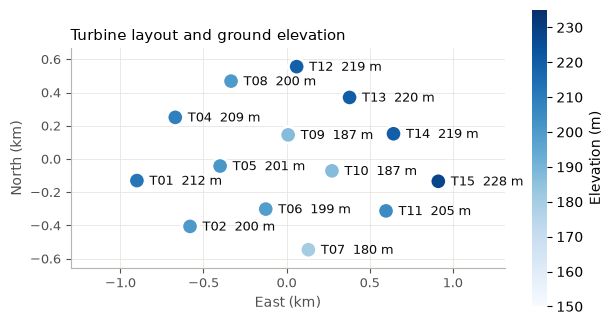

Nearest-neighbour spacing: 4.2 to 5.1 rotor diameters (median 4.4)


In [4]:
lat0 = np.deg2rad(turbines["latitude"].mean())
x_km = (turbines["longitude"] - turbines["longitude"].mean()) * 111.32 * np.cos(lat0)
y_km = (turbines["latitude"] - turbines["latitude"].mean()) * 110.57

fig, ax = plt.subplots(figsize=(7, 5.5))
sc = ax.scatter(x_km, y_km, c=turbines["elevation_m"], cmap="Blues", vmin=150, vmax=235, s=140,
                edgecolor="white", linewidth=2, zorder=3)
for x, y, t, e in zip(x_km, y_km, turbines["turbine_id"], turbines["elevation_m"]):
    ax.annotate(f"{label(t)}  {e:.0f} m", (x, y), xytext=(9, -3), textcoords="offset points",
                fontsize=9, color=INK)
ax.set_aspect("equal")
ax.margins(x=0.22, y=0.1)  # room for the labels
ax.set_xlabel("East (km)", color=MUTED)
ax.set_ylabel("North (km)", color=MUTED)
ax.set_title("Turbine layout and ground elevation", loc="left", fontsize=11)
cb = fig.colorbar(sc, ax=ax, shrink=0.7, label="Elevation (m)")
cb.outline.set_visible(False)
style_ax(ax)
plt.show()

# Nearest-neighbour spacing in rotor diameters
xy = np.c_[x_km, y_km]
d = np.sqrt(((xy[:, None] - xy[None]) ** 2).sum(-1)) * 1000 / turbines["rotor_diameter_m"].iloc[0]
np.fill_diagonal(d, np.inf)
print(f"Nearest-neighbour spacing: {d.min(1).min():.1f} to {d.min(1).max():.1f} rotor diameters "
      f"(median {np.median(d.min(1)):.1f})")

## Turbines: SCADA coverage

Monthly share of 10-minute slots in which each turbine reported active power. Light cells are months with gaps; white is no data at all. T01–T10 have no export for January 2023. The farm was commissioned in mid-2016 (commercial operations from September), so the first months are partial.

In [5]:
cov_rows, summary = [], []
for t in TURBINE_IDS:
    d = pd.read_parquet(DATA / "scada" / f"{t}.parquet", columns=["time_stamp", "power", "wind_speed"])
    ok = d.set_index("time_stamp")["power"].notna()
    monthly = ok.resample("MS").sum()
    slots = monthly.index.days_in_month * 144
    cov_rows.append((monthly / slots).rename(label(t)))
    summary.append({"turbine": label(t), "first": d["time_stamp"].min(), "last": d["time_stamp"].max(),
                    "rows": len(d), "power_missing_%": 100 * d["power"].isna().mean(),
                    "wind_speed_missing_%": 100 * d["wind_speed"].isna().mean(),
                    "mean_power_kW": d["power"].mean()})
coverage = pd.concat(cov_rows, axis=1).T
scada_summary = pd.DataFrame(summary).set_index("turbine")
scada_summary.round({"power_missing_%": 1, "wind_speed_missing_%": 1, "mean_power_kW": 0})

,first,last,rows,power_missing_%,wind_speed_missing_%,mean_power_kW
turbine,,,,,,
T01,2016-06-06 18:10:00,2023-12-31 23:50:00,393587,1.3,1.3,661.0
T02,2016-06-03 08:50:00,2023-12-31 23:50:00,394075,1.6,1.7,628.0
T04,2016-06-13 14:50:00,2023-12-31 23:50:00,392599,1.3,1.3,642.0
T05,2016-06-15 18:50:00,2023-12-31 23:50:00,392287,1.2,1.3,604.0
T06,2016-06-02 18:00:00,2023-12-31 23:50:00,394164,1.9,1.9,602.0
T07,2016-06-02 17:40:00,2023-12-31 23:50:00,394166,1.8,1.8,549.0
T08,2016-07-27 15:40:00,2023-12-31 23:50:00,386258,1.8,1.8,612.0
T09,2016-06-24 11:40:00,2023-12-31 23:50:00,391034,3.1,3.1,539.0
T10,2016-06-27 18:00:00,2023-12-31 23:50:00,390564,3.3,4.4,527.0


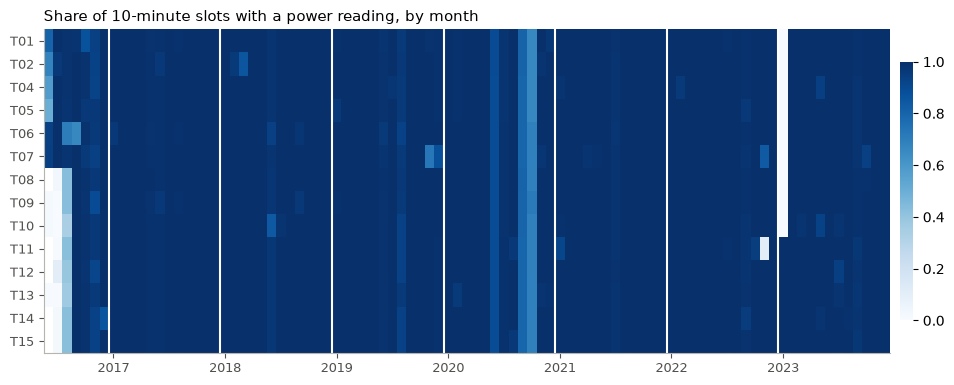

85 turbine-months below 90% coverage (excluding months with no data at all)


,turbine,time_stamp,coverage
5,T01,2023-01-01,0.00
11,T02,2023-01-01,0.00
21,T05,2023-01-01,0.00
16,T04,2023-01-01,0.00
27,T06,2023-01-01,0.00
42,T09,2016-07-01,0.00
40,T08,2023-01-01,0.00
34,T07,2023-01-01,0.00
48,T09,2023-01-01,0.00
50,T10,2016-07-01,0.00


In [6]:
fig, ax = plt.subplots(figsize=(13, 4.2))
months = coverage.columns
im = ax.imshow(coverage.to_numpy(dtype=float), aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="none")
ax.set_yticks(range(len(coverage)), coverage.index)
year_starts = [i for i, m in enumerate(months) if m.month == 1]
ax.set_xticks(year_starts, [months[i].year for i in year_starts])
for i in year_starts:
    ax.axvline(i - 0.5, color="white", lw=1.5)
ax.set_title("Share of 10-minute slots with a power reading, by month", loc="left", fontsize=11)
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.01)
cb.outline.set_visible(False)
style_ax(ax, grid_axis=None)
plt.show()

low = coverage.stack()
low = low[low < 0.9].rename("coverage").reset_index().rename(columns={"level_0": "turbine", "level_1": "month"})
print(f"{len(low)} turbine-months below 90% coverage (excluding months with no data at all)")
low.sort_values("coverage").head(20).round({"coverage": 2})

## SCADA signals

`feature_description` lists all 372 columns. Each signal has its 10-minute mean (`stat` empty) and usually `min`, `max` and `std`. Many columns are availability and energy-accounting counters rather than sensor readings, and some only exist in the 2023 exports. Share of non-null values per column (T01, whole period) comes from the Parquet metadata, so no data is loaded.

In [7]:
def non_null_share(path):
    meta = pq.ParquetFile(path).metadata
    nulls = {meta.schema.column(j).name: 0 for j in range(meta.num_columns)}
    for i in range(meta.num_row_groups):
        rg = meta.row_group(i)
        for j in range(rg.num_columns):
            col = rg.column(j)
            nulls[col.path_in_schema] += col.statistics.null_count if col.statistics is not None else 0
    return pd.Series({c: 1 - n / meta.num_rows for c, n in nulls.items()})

fd = features.drop_duplicates("column").set_index("column")  # mm/ss and mm/s2 labels share a column
fd["non_null_T01"] = non_null_share(DATA / "scada" / "1.parquet")
fd["stat"] = fd["stat"].fillna("mean")
print(fd["stat"].value_counts().to_dict())
print(fd["unit"].value_counts(dropna=False).to_dict())

{'mean': 158, 'min': 72, 'max': 72, 'std': 70}
{'°C': 80, 'kWh': 47, '°': 32, nan: 31, 'A': 28, 'kW': 25, 'V': 16, 'RPM': 16, 'kvarh': 16, 'm/s': 14, 's': 12, 'mm/s2': 12, 'Nm': 12, 'bar': 8, '%': 5, 'cosphi': 4, 'kvar': 4, 'Hz': 4, 'kVA': 4, 'h': 2}


In [8]:
# One row per signal (mean column): unit, which stats exist, and T01 availability.
signals = (fd.reset_index().groupby("name", sort=False)
           .agg(unit=("unit", "first"), stats=("stat", lambda s: ",".join(s)),
                mean_column=("column", "first"), non_null_T01=("non_null_T01", "max"))
           .sort_values("non_null_T01", ascending=False))
print(f"{len(signals)} signals; {(signals['non_null_T01'] > 0.9).sum()} are present >90% of the time for T01, "
      f"{(signals['non_null_T01'] < 0.2).sum()} under 20%")
signals.style.format({"non_null_T01": "{:.0%}"}).bar(subset="non_null_T01", color="#cde2fb", vmin=0, vmax=1)

160 signals; 94 are present >90% of the time for T01, 26 under 20%


,unit,stats,mean_column,non_null_T01
name,,,,
Long Term Wind,m/s,mean,long_term_wind,100%
Energy Budget - Default,kWh,mean,energy_budget_default,100%
Available Capacity for Production (Planned),kW,mean,available_capacity_for_production_planned,100%
Virtual Production,kWh,mean,virtual_production,100%
Data Availability,nan,mean,data_availability,100%
Time-based System Avail. (Planned),nan,mean,time_based_system_avail_planned,100%
Lost Production to Curtailment (Grid),kWh,mean,lost_production_to_curtailment_grid,100%
Lost Production to Curtailment (Total),kWh,mean,lost_production_to_curtailment_total,100%
Lost Production Total,kWh,mean,lost_production_total,100%


## Status data

Each turbine's status log records state changes from the turbine controller. Columns:

- `status`: severity class (Informational, Warning, Stop, Communication, Curtailment)
- `code` / `message`: the Senvion status code and its text
- `service_contract_category`: the code's group in the service contract, e.g. *Pitch errors (18)*
- `iec_category`: IEC 61400-26 availability category, e.g. *Forced outage*, *Scheduled Maintenance*
- `comment`: operator free text (rare)
- `global_contract_category` / `custom_contract_category`: only in the 2023 exports

**Logging changed in 2018.** Before then almost every row is a timed state with a start and end. From 2018 on, the log also records many point-in-time messages with no end time or duration, so the row count per year jumps about fourfold. Count-based statistics are therefore not comparable across that change. Durations of timed states (Stops in particular) are.

In [9]:
by_year = (status.assign(year=status["timestamp_start"].dt.year)
           .pivot_table(index="year", columns="status", values="code", aggfunc="size", observed=True, fill_value=0))
by_year["no end time %"] = (status.assign(year=status["timestamp_start"].dt.year)
                            .groupby("year")["timestamp_end"].apply(lambda s: 100 * s.isna().mean()).round(1))
by_year

status,Communication,Curtailment,Informational,Stop,Warning,no end time %
year,,,,,,
2016,0,0,14095,2027,2366,0.3
2017,0,0,32041,2072,734,0.1
2018,132,0,122437,2170,1092,79.1
2019,175,0,146223,2047,922,86.5
2020,308,0,154067,3267,866,86.6
2021,291,14,183564,2713,2173,85.4
2022,164,80,149990,3000,2242,85.4
2023,121,13,164403,2725,1347,86.0


In [10]:
print("Share of rows with an end time, by status:")
print(status.groupby("status", observed=True)["timestamp_end"].apply(lambda s: f"{s.notna().mean():.1%}").to_string())
status.pivot_table(index="turbine_id", columns="status", values="code", aggfunc="size", observed=True,
                   fill_value=0).rename(index=label)

Share of rows with an end time, by status:
status
Communication    100.0%
Curtailment      100.0%
Informational     16.7%
Stop             100.0%
Warning           99.7%


status,Communication,Curtailment,Informational,Stop,Warning
turbine_id,,,,,
T01,90,8,62629,1397,616
T02,86,8,76036,1469,799
T04,95,7,64471,1365,729
T05,88,8,83354,1356,838
T06,85,8,72976,1385,1187
T07,89,8,83863,1254,811
T08,79,6,69870,1518,1010
T09,77,8,76811,1352,1076
T10,92,8,80297,1271,691


### IEC availability categories

Total time per IEC category, from timed rows only. Timed rows can overlap (a Stop usually sits inside a longer state), so the hours are time *tagged* with each category, not a partition of the calendar.

In [11]:
timed = status[status["duration"].notna()]
iec = (timed.groupby("iec_category", observed=True, dropna=False)
       .agg(rows=("code", "size"), hours=("duration", lambda d: d.sum() / pd.Timedelta("1h")))
       .sort_values("hours", ascending=False))
years = (status["timestamp_start"].max() - status["timestamp_start"].min()) / pd.Timedelta(days=365.25)
iec["hours_per_turbine_year"] = iec["hours"] / (len(TURBINE_IDS) * years)
iec.round(1)

,rows,hours,hours_per_turbine_year
iec_category,,,
Full Performance,35223,279973.7,2638.7
NaN,9150,135232.2,1274.5
Partial Performance,1800,21675.3,204.3
Forced outage,5644,18766.8,176.9
Scheduled Maintenance,2228,11176.2,105.3
Requested Shutdown,268,6990.7,65.9
Out of Environmental Specification,131830,4621.3,43.6
Technical Standby,8446,2801.7,26.4
Out of Electrical Specification,345,2723.7,25.7


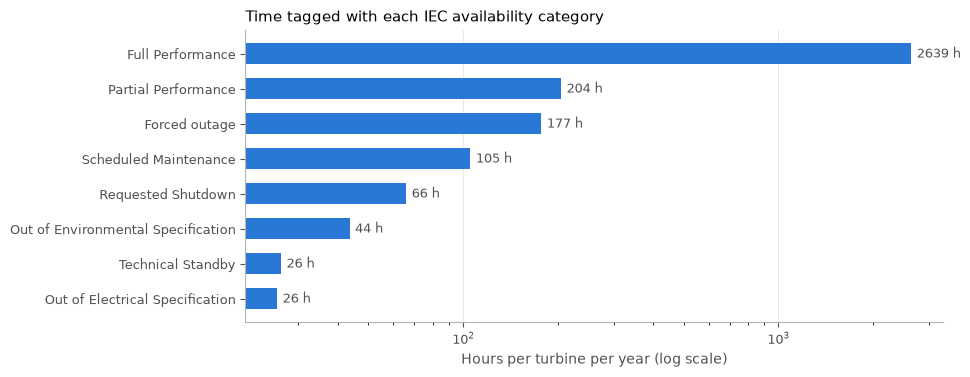

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.8))
plot = iec.drop(index=[i for i in iec.index if pd.isna(i)])["hours_per_turbine_year"].iloc[::-1]
bars = ax.barh(plot.index.astype(str), plot.values, color=PALETTE[0], height=0.6)
ax.bar_label(bars, fmt="%.0f h", padding=4, fontsize=9, color=MUTED)
ax.set_xscale("log")
ax.set_xlabel("Hours per turbine per year (log scale)", color=MUTED)
ax.set_title("Time tagged with each IEC availability category", loc="left", fontsize=11)
style_ax(ax, grid_axis="x")
plt.show()

## Event logs: Stop events

Stop events are the closest thing to fault records: the turbine stopped producing. Not every Stop is a fault, though. Many are environmental (high wind, icing, cable unwinding), grid-side, or deliberate (manual and park-master stops, maintenance). The service contract category separates these, grouped here into six classes.

In [13]:
STOP_GROUPS = {  # service_contract_category -> class (colour order = PALETTE order)
    "Turbine fault": ["Generator and Converter errors (20)", "Pitch errors (18)", "Mechanical error (23)",
                      "Electrical error (24)", "Sensor error (21)", "Temperature error (22)",
                      "Controller error of the WP3100 (16)", "Repeated error  (25)", "Safety chain (13)",
                      "Safety stop of WEC (15)", "Emergency stop switch (Converter) (12)",
                      "Emergency stop switch (Nacelle) (11)", "WEC Shutdown (1)", "Overspeed (14)"],
    "Manual / service": ["Manual stop (service)  (9)"],
    "Remote / park stop": ["Remote stop (30)"],
    "Grid": ["External stop (grid) (4)"],
    "Environment": ["External stop (low wind speed)  (5)", "External stop (climate) (6)"],
    "Operating state": ["Operating states  (28)", "Warnings (27)"],
}
GROUP_OF = {cat: g for g, cats in STOP_GROUPS.items() for cat in cats}
GROUP_COLOR = dict(zip(STOP_GROUPS, PALETTE))

stops = status[status["status"] == "Stop"].copy()
stops["group"] = stops["service_contract_category"].astype(str).map(GROUP_OF).fillna("Other")
stops["hours"] = stops["duration"] / pd.Timedelta("1h")
print(f"{len(stops):,} Stop events, {stops['hours'].sum():,.0f} hours in total")
unmapped = stops.loc[stops["group"] == "Other", "service_contract_category"].value_counts(dropna=False)
if len(unmapped):
    print("Unmapped categories:", unmapped.to_dict())
(stops.groupby("group").agg(events=("code", "size"), hours=("hours", "sum"),
                            median_minutes=("hours", lambda h: 60 * h.median()))
 .sort_values("hours", ascending=False).round(1))

20,021 Stop events, 43,745 hours in total
Unmapped categories: {nan: 1}


,events,hours,median_minutes
group,,,
Turbine fault,3284,14247.0,10.3
Manual / service,2226,10764.9,43.1
Remote / park stop,563,10360.6,316.4
Grid,1602,2938.7,1.0
Environment,4255,2823.0,17.2
Operating state,8090,2610.8,2.3
Other,1,0.0,1.7


### Which codes cost the most downtime

Top Stop codes by total hours across the farm, coloured by class. Long manual and park-master stops dominate total hours. High-wind stops (`Max. wind speed`) and cable unwinding are frequent but short.

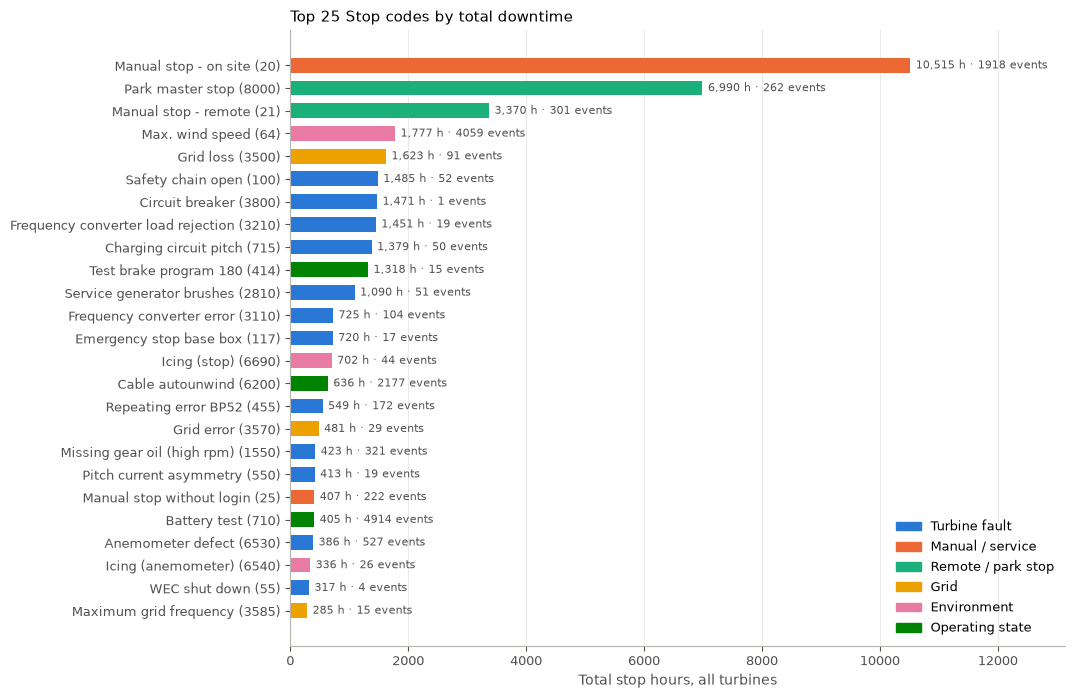

In [14]:
# A few codes appear under more than one contract category; give each code its most common class.
top = (stops.groupby(["code", "message"], observed=True)
       .agg(group=("group", lambda g: g.mode().iloc[0]), events=("code", "size"), hours=("hours", "sum"),
            turbines=("turbine_id", "nunique"))
       .reset_index().sort_values("hours", ascending=False))
top_n = top.head(25).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh([f"{m} ({c})" for c, m in zip(top_n["code"], top_n["message"])], top_n["hours"],
               color=[GROUP_COLOR.get(g, AXIS) for g in top_n["group"]], height=0.65)
ax.bar_label(bars, labels=[f"{h:,.0f} h · {n} events" for h, n in zip(top_n["hours"], top_n["events"])],
             padding=4, fontsize=8, color=MUTED)
ax.set_xlabel("Total stop hours, all turbines", color=MUTED)
ax.set_title("Top 25 Stop codes by total downtime", loc="left", fontsize=11)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLOR.values()],
          labels=list(GROUP_COLOR), loc="lower right", frameon=False, fontsize=9)
ax.set_xlim(0, top_n["hours"].max() * 1.25)
style_ax(ax, grid_axis="x")
plt.show()

In [15]:
# Turbine-fault codes only: the most likely candidates for fault labels.
top[top["group"] == "Turbine fault"].head(30).round(1)

,code,message,group,events,hours,turbines
9,100,Safety chain open,Turbine fault,52,1484.7,12
82,3800,Circuit breaker,Turbine fault,1,1471.2,1
70,3210,Frequency converter load rejection,Turbine fault,19,1450.6,12
42,715,Charging circuit pitch,Turbine fault,50,1379.4,13
65,2810,Service generator brushes,Turbine fault,51,1090.4,7
67,3110,Frequency converter error,Turbine fault,104,724.9,14
11,117,Emergency stop base box,Turbine fault,17,720.3,13
23,455,Repeating error BP52,Turbine fault,172,548.9,14
52,1550,Missing gear oil (high rpm),Turbine fault,321,423.3,14
25,550,Pitch current asymmetry,Turbine fault,19,413.4,7


### Stop timeline per turbine

Each bar is one Stop event, coloured by class. Events shorter than a few hours are barely visible at this scale, so long outages stand out. Vertical stripes across many turbines are farm-wide events (grid outages, park-master stops), such as the remote/park stop across the whole farm in September 2020, which is also the low-coverage stripe in the SCADA coverage plot. The cluster of long stops in June–August 2016 is commissioning, before commercial operation began on 2016-09-01.

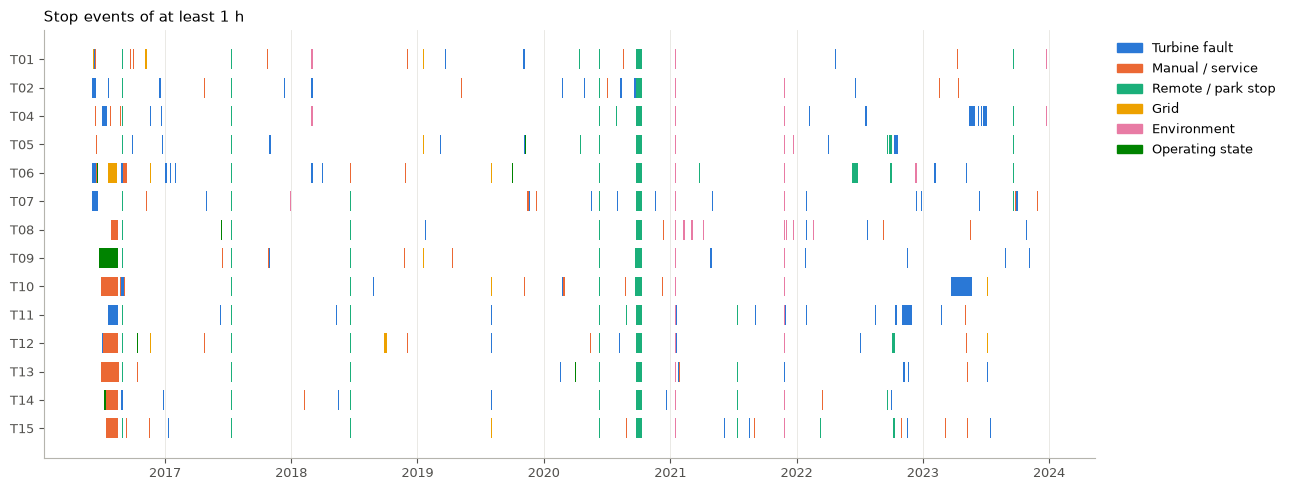

In [16]:
def stop_timeline(stops, groups=None, start=None, end=None, min_hours=0):
    sel = stops if groups is None else stops[stops["group"].isin(groups)]
    sel = sel[sel["hours"] >= min_hours]
    if start is not None:
        sel = sel[sel["timestamp_end"] >= pd.Timestamp(start)]
    if end is not None:
        sel = sel[sel["timestamp_start"] <= pd.Timestamp(end)]
    fig, ax = plt.subplots(figsize=(13, 5))
    for row, t in enumerate(TURBINE_IDS):
        ev = sel[sel["turbine_id"] == t]
        for g, evg in ev.groupby("group"):
            starts = mdates.date2num(evg["timestamp_start"])
            widths = mdates.date2num(evg["timestamp_end"]) - starts
            ax.broken_barh(list(zip(starts, widths)), (row - 0.35, 0.7), color=GROUP_COLOR.get(g, AXIS), lw=0)
    ax.set_yticks(range(len(TURBINE_IDS)), [label(t) for t in TURBINE_IDS])
    ax.invert_yaxis()
    ax.xaxis_date()
    if start is not None or end is not None:
        ax.set_xlim(pd.Timestamp(start) if start else None, pd.Timestamp(end) if end else None)
    shown = [g for g in GROUP_COLOR if g in set(sel["group"])]
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=GROUP_COLOR[g]) for g in shown], labels=shown,
              loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9)
    ax.set_title(f"Stop events{f' of at least {min_hours} h' if min_hours else ''}", loc="left", fontsize=11)
    style_ax(ax, grid_axis="x")
    fig.tight_layout()
    plt.show()

stop_timeline(stops, min_hours=1)

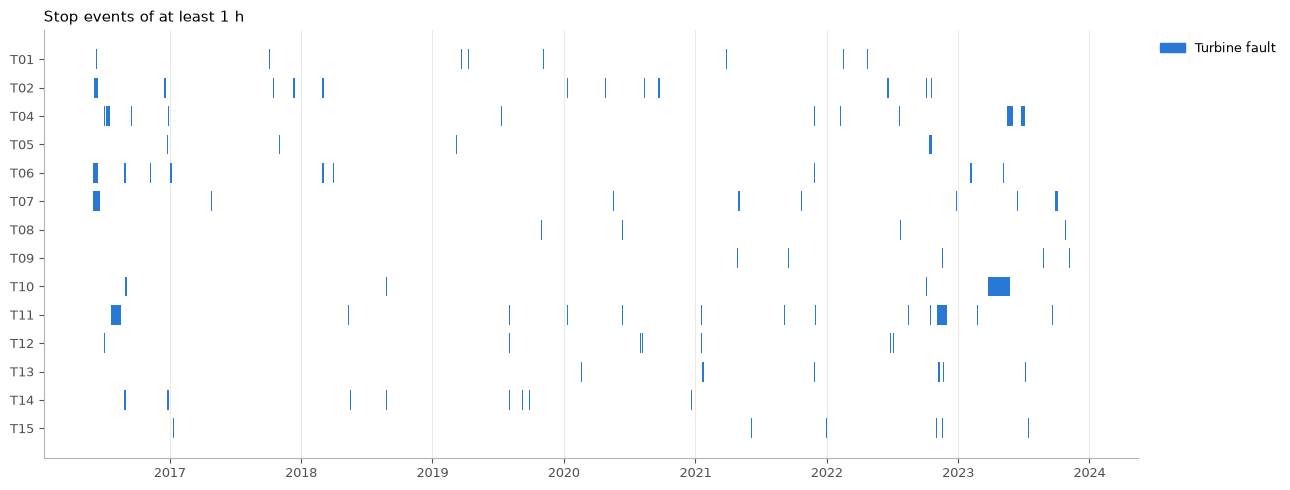

In [17]:
stop_timeline(stops, groups=["Turbine fault"], min_hours=1)

### Monthly turbine-fault downtime

Hours per turbine per month lost to Stop events in the *Turbine fault* class (single-hue scale, darker = more hours, capped at 100 h). This shows where the fault stops cluster, which is where a detector would have something to find.

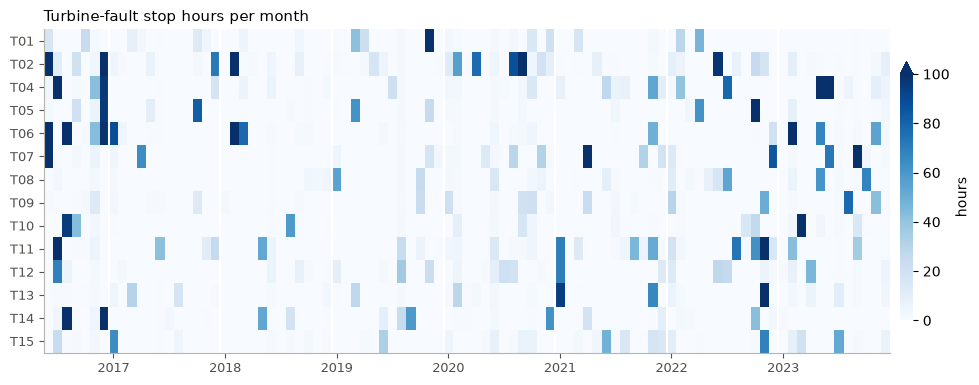

,turbine_id,timestamp_start,timestamp_end,hours,code,message,service_contract_category
679527,10,2023-03-24 01:43:36,2023-05-24 08:55:13,1471.2,3800,Circuit breaker,Electrical error (24)
679526,10,2023-03-24 01:43:36,2023-05-22 11:37:53,1425.9,3210,Frequency converter load rejection,Generator and Converter errors (20)
691333,11,2016-07-20 16:00:37,2016-08-19 12:11:19,716.2,117,Emergency stop base box,Emergency stop switch (Converter) (12)
742740,11,2022-11-02 07:44:29,2022-12-01 15:13:37,703.5,2810,Service generator brushes,Generator and Converter errors (20)
202908,4,2023-05-15 10:40:16,2023-06-01 12:37:46,410.0,20,Manual stop - on site,Generator and Converter errors (20)
371090,7,2016-06-02 17:45:07,2016-06-15 13:29:14,307.7,100,Safety chain open,Safety chain (13)
295449,6,2016-06-02 18:02:26,2016-06-15 11:58:03,305.9,100,Safety chain open,Safety chain (13)
204205,4,2023-06-23 14:08:57,2023-07-05 09:26:45,283.3,55,WEC shut down,WEC Shutdown (1)
64741,2,2016-06-03 08:54:48,2016-06-14 11:42:17,266.8,100,Safety chain open,Safety chain (13)
279204,5,2022-10-11 03:38:06,2022-10-21 14:26:07,250.8,715,Charging circuit pitch,Pitch errors (18)


In [18]:
fault_stops = stops[stops["group"] == "Turbine fault"]
monthly_fault = (fault_stops.groupby(["turbine_id", pd.Grouper(key="timestamp_start", freq="MS")])["hours"].sum()
                 .unstack(fill_value=0).reindex(index=TURBINE_IDS, columns=coverage.columns, fill_value=0))
fig, ax = plt.subplots(figsize=(13, 4.2))
im = ax.imshow(monthly_fault.to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=100, interpolation="none")
ax.set_yticks(range(len(TURBINE_IDS)), [label(t) for t in TURBINE_IDS])
ax.set_xticks(year_starts, [months[i].year for i in year_starts])
for i in year_starts:
    ax.axvline(i - 0.5, color="white", lw=1.5)
ax.set_title("Turbine-fault stop hours per month", loc="left", fontsize=11)
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.01, extend="max", label="hours")
cb.outline.set_visible(False)
style_ax(ax, grid_axis=None)
plt.show()

longest = fault_stops.sort_values("hours", ascending=False).head(15)
longest[["turbine_id", "timestamp_start", "timestamp_end", "hours", "code", "message",
         "service_contract_category"]].round({"hours": 1})

### Operator comments

Free-text comments are rare but explain some long stops (maintenance campaigns, testing, comms loss).

In [19]:
comments = status[status["comment"].notna()]
print(f"{len(comments):,} rows with a comment ({len(comments) / len(status):.2%})")
(comments.groupby("comment", observed=True)
 .agg(rows=("code", "size"), turbines=("turbine_id", lambda s: sorted(s.unique())),
      first=("timestamp_start", "min"), last=("timestamp_start", "max"))
 .sort_values("rows", ascending=False).head(25))

522 rows with a comment (0.05%)


,rows,turbines,first,last
comment,,,,
Turbine HV and Converter Maintenance,98,"[1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]",2022-09-19 07:30:52,2023-09-21 07:20:59
Tower displacement testing,56,"[1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]",2023-02-09 08:37:00,2023-02-10 13:52:03
Ended by code 0,44,"[1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]",2022-11-02 11:19:55,2023-10-02 05:55:51
High Winds,25,"[1, 2, 4, 5, 6, 8, 10, 11, 12, 13, 14, 15]",2023-02-02 21:55:15,2023-02-17 09:42:27
Delayed 2022 annual and 2023 semi-annual service,19,"[1, 8, 9, 11, 12, 13, 14, 15]",2023-05-02 07:31:23,2023-05-15 08:04:47
Gear oil exchange,16,"[1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]",2023-11-01 07:53:25,2023-12-13 12:12:56
BoP HV Maintenance,14,"[1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]",2023-07-11 07:41:52,2023-07-11 07:41:53
Annual HV Maintenance,13,"[1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15]",2022-07-05 07:00:01,2022-07-05 07:00:02
Loss of comms to Greenbyte - SGRE restarted the IEC server.,13,"[1, 2, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15]",2022-11-25 15:45:46,2022-11-25 15:46:06


### A fault stop in the SCADA data

The longest turbine-fault stop, with that turbine's power and wind speed for two weeks either side. The shaded span is the stop. This checks that the status log and the SCADA agree: power should drop to zero while wind continues.

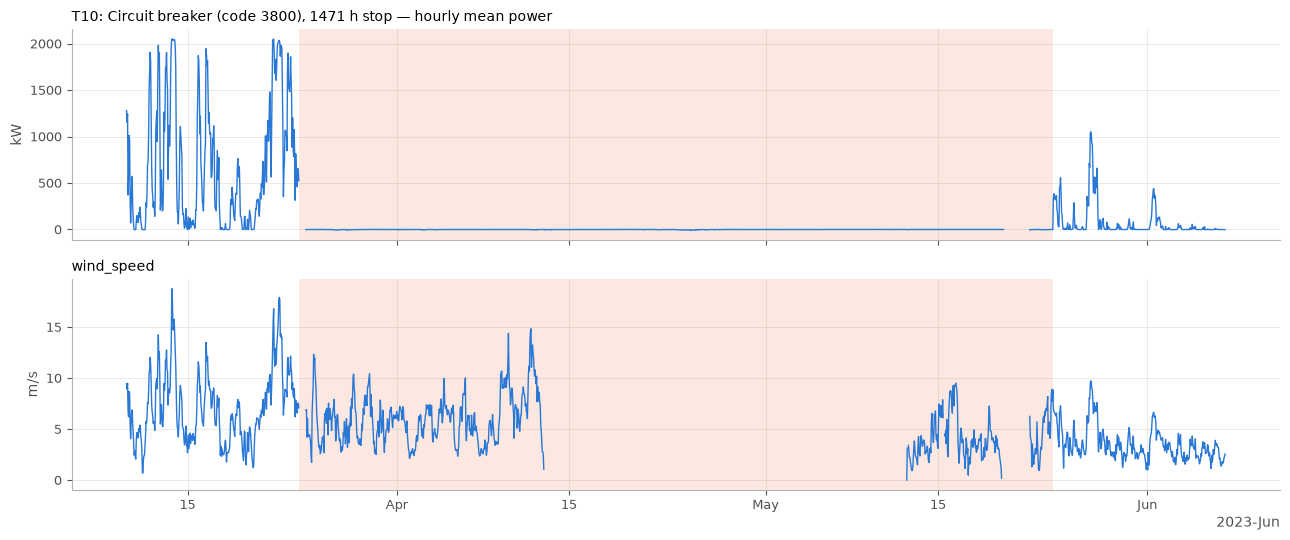

In [20]:
ev = longest.iloc[0]
t = int(ev["turbine_id"])
lo, hi = ev["timestamp_start"] - pd.Timedelta(days=14), ev["timestamp_end"] + pd.Timedelta(days=14)
d = pd.read_parquet(DATA / "scada" / f"{t}.parquet", columns=["time_stamp", "power", "wind_speed"],
                    filters=[("time_stamp", ">=", lo), ("time_stamp", "<=", hi)]).set_index("time_stamp")
d = d.resample("1h").mean()

fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
for ax, col, unit in zip(axes, ["power", "wind_speed"], ["kW", "m/s"]):
    ax.plot(d.index, d[col], color=PALETTE[0], lw=1)
    ax.axvspan(ev["timestamp_start"], ev["timestamp_end"], color=PALETTE[1], alpha=0.15, lw=0)
    ax.set_ylabel(unit, color=MUTED)
    ax.set_title(col, loc="left", fontsize=10)
    style_ax(ax)
axes[0].set_title(f"{label(t)}: {ev['message']} (code {ev['code']}), {ev['hours']:.0f} h stop — hourly mean power",
                  loc="left", fontsize=10)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(axes[1].xaxis.get_major_locator()))
fig.tight_layout()
plt.show()

## Notes

- **Events and labels:** *Turbine fault* Stop events, with their start and end times, can serve as fault windows, much as CARE to Compare labels the period before an anomaly event. Short fault stops (a few minutes, auto-reset) are frequent and probably not useful as labels; filter by duration.
- **Logging change:** status rows are not comparable in count across the 2018 change; use Stop durations instead.
- **Commissioning:** data before 2016-09-01 is commissioning (long safety-chain and manual stops, gaps). Exclude it from training and evaluation.
- **Farm-wide stops:** grid and park-master stops affect all turbines at once and are not turbine faults, but they should be excluded from "normal" training data.